# Put learned steps all together

## 0. Imports and Envs

In [76]:
import torch
from torch import nn
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

torch.__version__

'2.12.0+cu126'

In [77]:
# device-agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using device: {device}")

using device: cuda


## 1. Data

In [78]:
# 1. define linear params for mock data
weight = 0.6
bias = 0.2

# 2. generate data
start = 1
end = 2
step = 0.02
X = torch.arange(start, end, step).unsqueeze(dim=1).to(device)
y = X * weight + bias

# 3. 划分数据集
percent = 0.8
train_len = int(len(X) * percent)
X_train, y_train = X[:train_len], y[:train_len]
X_test, y_test = X[train_len:], y[train_len:]

In [79]:
# 4. 定义可视化函数
def plot_data(X_train=X_train.cpu(), y_train=y_train.cpu(),
              X_test=X_test.cpu(), y_test=y_test.cpu(),
              predictions=None):
    plt.figure(figsize=(10, 7))
    plt.scatter(X_train, y_train, s=8, c='r', label="Training Data")
    plt.scatter(X_test, y_test, s=8, c='b', label="Testing Data")
    if predictions is not None:
        predictions = predictions.cpu()
        plt.scatter(X_test, predictions, s=8, c='g', label="Predictions")
    plt.legend()

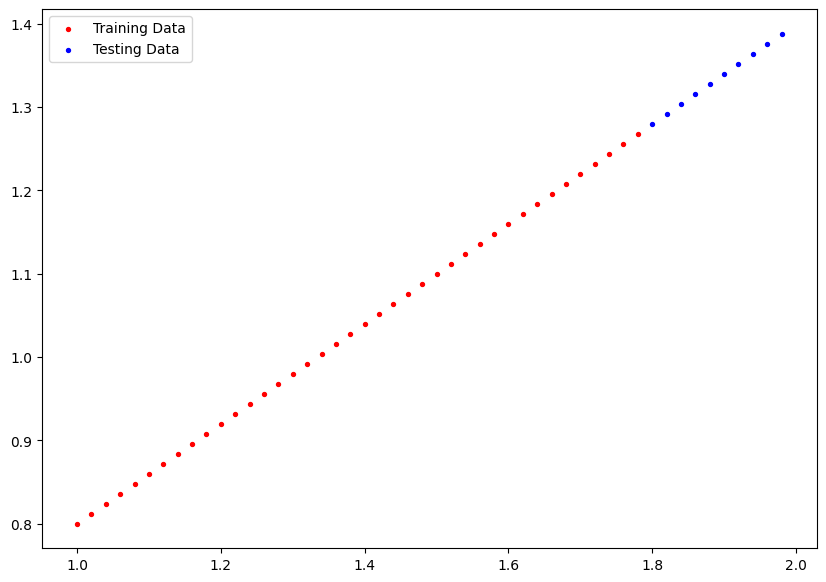

In [80]:
# 可视化数据
plot_data()

## 2. Build Model

In [81]:
# 0. random_seed
RAND_SEED = 42
torch.manual_seed(RAND_SEED)

# 1. define model
class LinearRegressionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer = nn.Linear(in_features=1, out_features=1)
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)

In [82]:
# 2. make a model instance
my_model = LinearRegressionModel().to(device)
my_model.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.7645]], device='cuda:0')),
             ('linear_layer.bias', tensor([0.8300], device='cuda:0'))])

## 3. Train the model

In [83]:
# 1. Loss Function
loss_fn = nn.L1Loss()

# 2. Optimizer
optimimzer = torch.optim.SGD(params=my_model.parameters(),
                             lr=0.01)

In [84]:
# 3. Train Loop
epoches = 300

epoch_count = []
train_loss_lst = []
test_loss_lst = []

for epoch in range(epoches):
    # training
    my_model.train()
    # 1. forward pass
    train_pred = my_model(X_train)
    
    # 2. Caculate Loss
    train_loss = loss_fn(train_pred, y_train)
    
    # 3. optimizer zero_grad
    optimimzer.zero_grad()
    
    # 4. loss back propagation
    train_loss.backward()
    
    # 5. optimizer step
    optimimzer.step()
    
    # testing
    my_model.eval()
    with torch.inference_mode():
        # 1. forward pass
        test_pred = my_model(X_test)
        # 2. caculate loss
        test_loss = loss_fn(test_pred, y_test)
        
        if epoch % 20 == 0:
            epoch_count.append(epoch)
            train_loss_lst.append(train_loss.cpu().numpy())
            test_loss_lst.append(test_loss.cpu().numpy())
            print(f"epoch: {epoch} | train loss: {train_loss} | test loss: {test_loss}\n{my_model.state_dict()}")

epoch: 0 | train loss: 0.8587164282798767 | test loss: 0.9047145843505859
OrderedDict({'linear_layer.weight': tensor([[0.7506]], device='cuda:0'), 'linear_layer.bias': tensor([0.8200], device='cuda:0')})


epoch: 20 | train loss: 0.27229711413383484 | test loss: 0.17929543554782867
OrderedDict({'linear_layer.weight': tensor([[0.4726]], device='cuda:0'), 'linear_layer.bias': tensor([0.6200], device='cuda:0')})
epoch: 40 | train loss: 0.046499092131853104 | test loss: 0.10437975078821182
OrderedDict({'linear_layer.weight': tensor([[0.3710]], device='cuda:0'), 'linear_layer.bias': tensor([0.5285], device='cuda:0')})
epoch: 60 | train loss: 0.04380292445421219 | test loss: 0.10207761824131012
OrderedDict({'linear_layer.weight': tensor([[0.3828]], device='cuda:0'), 'linear_layer.bias': tensor([0.5085], device='cuda:0')})
epoch: 80 | train loss: 0.04112493619322777 | test loss: 0.09424979984760284
OrderedDict({'linear_layer.weight': tensor([[0.3967]], device='cuda:0'), 'linear_layer.bias': tensor([0.4900], device='cuda:0')})
epoch: 100 | train loss: 0.03845112398266792 | test loss: 0.08826382458209991
OrderedDict({'linear_layer.weight': tensor([[0.4099]], device='cuda:0'), 'linear_layer.bias':

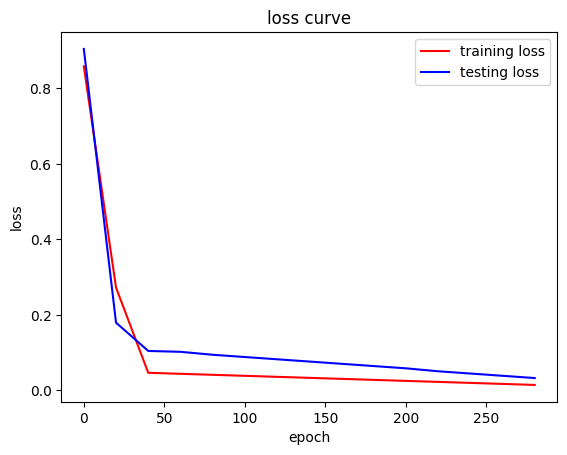

In [85]:
# draw loss curve
plt.plot(epoch_count, train_loss_lst, c='r', label="training loss")
plt.plot(epoch_count, test_loss_lst, c='b', label="testing loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("loss curve")
plt.legend()

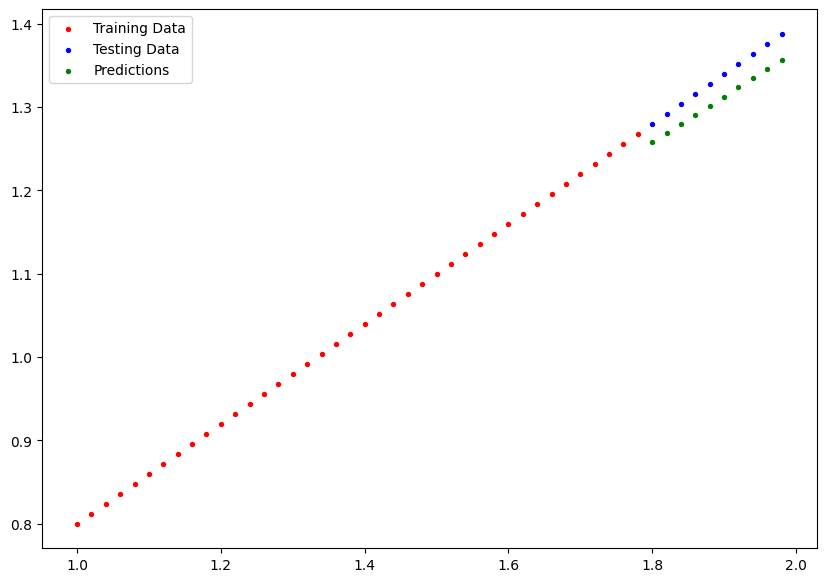

In [86]:
# make predictions
with torch.inference_mode():
    preds = my_model(X_test)
    
plot_data(predictions=preds)

## 4. Save and Load the model

In [87]:
# Make Folder if not exist and set path
MODEL_FOLDER = Path("Model")
MODEL_FOLDER.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "01_rewrite_model.pt"
MODEL_SAVE_PATH = MODEL_FOLDER / MODEL_NAME

# save model
torch.save(obj=my_model.state_dict(),
           f=MODEL_SAVE_PATH)

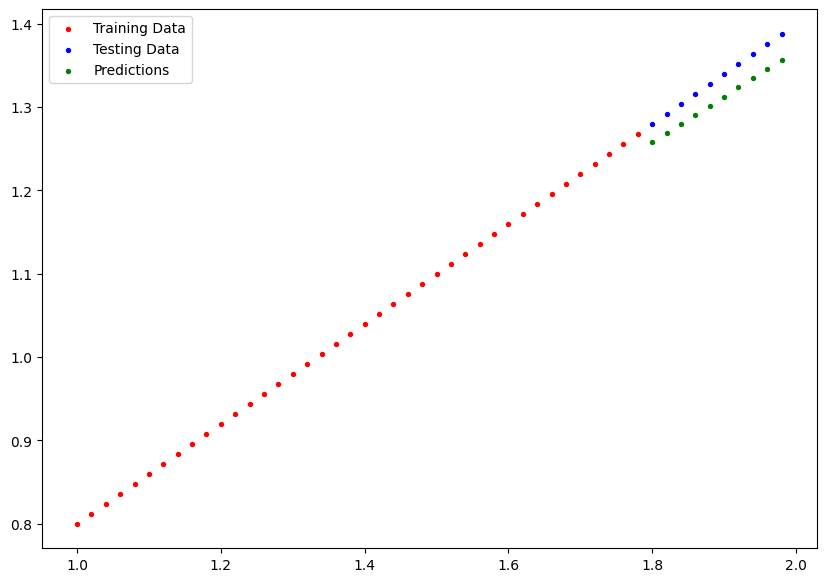

In [88]:
# load model and make predictions
loaded_model = LinearRegressionModel().to(device)
loaded_model.load_state_dict(torch.load(f=MODEL_SAVE_PATH, weights_only=True))

loaded_model.eval()
with torch.inference_mode():
    lm_preds = loaded_model(X_test)
plot_data(predictions=lm_preds)